# 6 · The Exact Answer

Count **every** frequent itemset in the 100,000 planted baskets, with its exact support. This is the answer key the
model will be scored against. Apriori twice: a plain version to understand it, then a bitset version that's fast
enough for 100,000 baskets at 0.05%.

**Done when:** my miner is identical to the reference miner and the dataset's truth, and my labels match the reference.

In [1]:
import math
import time
from collections import Counter
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from thilimarketbasket.dataset import generate_dataset, classify_itemset
from thilimarketbasket.mine import frequent_itemsets as reference_miner, rules

data = generate_dataset(n_baskets=100_000, seed=0)     # sections 1 to 5, in one call (about 10 seconds)
baskets = data.baskets
print(f"{len(baskets):,} baskets, {len(data.planted)} planted itemsets")

100,000 baskets, 32 planted itemsets


## The idea on six baskets

A set can only be frequent if all its parts are. So count in levels: singles → pairs built from frequent singles →
triples built from frequent pairs → … until nothing survives.

In [2]:
toy = [
    ["tea", "sugar", "milk"], ["tea", "sugar"], ["bread", "butter", "milk"],
    ["tea", "milk"], ["bread", "butter"], ["tea", "sugar", "bread"],
]
toy_items = sorted({item for basket in toy for item in basket})

print(f"{len(toy_items)} items. Itemsets of every size a brute-force miner would look at: "
      f"{sum(math.comb(len(toy_items), k) for k in range(1, len(toy_items) + 1))}")

5 items. Itemsets of every size a brute-force miner would look at: 31


## Version 1: plain Apriori

Each level: **join** frequent k-sets into (k+1)-candidates, **prune** any with an infrequent part, **count** by
scanning baskets.

In [3]:
def plain_apriori(baskets, min_support, max_size=5):
    n = len(baskets)
    min_count = max(1, math.ceil(min_support * n - 1e-9))     # the allowance guards 0.0005 * 100000
    basket_sets = [frozenset(basket) for basket in baskets]   # quantity does not matter: two milks count as milk

    counts = Counter(item for basket in basket_sets for item in basket)
    level = {frozenset([item]): c for item, c in counts.items() if c >= min_count}
    found = dict(level)

    size = 1
    while level and size < max_size:
        candidates = set()
        for a, b in combinations(level, 2):                   # JOIN
            union = a | b
            if len(union) == size + 1 and all(union - {x} in level for x in union):   # PRUNE
                candidates.add(union)
        counts = Counter()
        for basket in basket_sets:                            # COUNT
            for candidate in candidates:
                if candidate <= basket:
                    counts[candidate] += 1
        level = {c: k for c, k in counts.items() if k >= min_count}
        found.update(level)
        size += 1
    return {itemset: count / n for itemset, count in found.items()}


for itemset, support in sorted(plain_apriori(toy, 0.5).items(), key=lambda kv: (len(kv[0]), sorted(kv[0]))):
    print(f"{support:.2f}  {' + '.join(sorted(itemset))}")

0.50  bread
0.50  milk
0.50  sugar
0.67  tea
0.50  sugar + tea


Same as the hand count in section 0. Now 2,000 real baskets at 1%:

In [4]:
sample = baskets[:2000]

start = time.time()
slow = plain_apriori(sample, 0.01)
print(f"plain Apriori: {len(slow)} frequent itemsets in {time.time() - start:.1f} s")
print("by size:", dict(sorted(Counter(len(s) for s in slow).items())))

plain Apriori: 471 frequent itemsets in 2.8 s
by size: {1: 243, 2: 168, 3: 45, 4: 13, 5: 2}


Seconds for only 2,000 baskets — the count step tests every candidate against every basket.

## Version 2: one bitset per item

Each item gets a long integer with bit *i* set if basket *i* holds it. Then "baskets holding both" is one `&`, and
support is `bit_count()`.

In [5]:
bits = {item: sum(1 << number for number, basket in enumerate(toy) if item in basket) for item in toy_items}

for item, value in bits.items():
    print(f"{item:7} {value:06b}")

both = bits["tea"] & bits["sugar"]
print(f"\ntea AND sugar = {both:06b}   -> {both.bit_count()} baskets hold both")

bread   110100
butter  010100
milk    001101
sugar   100011
tea     101011

tea AND sugar = 100011   -> 3 baskets hold both


The fast miner: same join/prune/count, but the join only combines sets sharing all but the last item (each candidate
built once), and the count is a single AND of the parent's bitset with the new item's.

In [6]:
def bitsets(baskets):
    """One big integer per item: bit i is 1 when basket i holds the item."""
    numbers_of = {}
    for number, basket in enumerate(baskets):
        for item in set(basket):
            numbers_of.setdefault(item, []).append(number)
    result = {}
    for item, numbers in numbers_of.items():
        held = np.zeros(len(baskets), dtype=bool)
        held[numbers] = True
        result[item] = int.from_bytes(np.packbits(held).tobytes(), "big")
    return result


def my_frequent_itemsets(baskets, min_support, max_size=5):
    n = len(baskets)
    min_count = max(1, math.ceil(min_support * n - 1e-9))
    bits = bitsets(baskets)

    level = {(item,): value for item, value in bits.items() if value.bit_count() >= min_count}
    found = {frozenset(items): value.bit_count() / n for items, value in level.items()}

    size = 1
    while level and size < max_size:
        by_prefix = {}                                    # itemsets that agree on all but their last item
        for items in sorted(level):
            by_prefix.setdefault(items[:-1], []).append(items[-1])
        next_level = {}
        for prefix, lasts in by_prefix.items():
            for a, b in combinations(lasts, 2):           # JOIN: a < b because `lasts` is sorted
                candidate = prefix + (a, b)
                if any(candidate[:i] + candidate[i + 1:] not in level for i in range(len(candidate) - 2)):
                    continue                              # PRUNE
                held = level[prefix + (a,)] & bits[b]     # COUNT: one AND
                if held.bit_count() >= min_count:
                    next_level[candidate] = held
        level = next_level
        found.update({frozenset(items): value.bit_count() / n for items, value in level.items()})
        size += 1
    return found


print("toy example matches plain Apriori:", my_frequent_itemsets(toy, 0.5) == plain_apriori(toy, 0.5))

start = time.time()
fast = my_frequent_itemsets(sample, 0.01)
print(f"bitset Apriori on the same 2,000 baskets: {time.time() - start:.3f} s, same answer as plain: {fast == slow}")

toy example matches plain Apriori: True
bitset Apriori on the same 2,000 baskets: 0.014 s, same answer as plain: True


## Check against the reference: full data at 0.05% (= 50 baskets, the rarest planted support)

In [7]:
start = time.time()
truth = my_frequent_itemsets(baskets, min_support=0.0005, max_size=5)
print(f"{len(truth):,} frequent itemsets in {time.time() - start:.1f} s")

print("identical to the reference miner:", truth == reference_miner(baskets, 0.0005, 5))
print("identical to the dataset's truth: ", truth == data.truth)

56,470 frequent itemsets in 4.5 s


identical to the reference miner: True
identical to the dataset's truth:  True


## What's in the truth

In [8]:
by_size = pd.Series(Counter(len(itemset) for itemset in truth)).sort_index()
print(by_size.rename("itemsets").to_frame().T.to_string(index=False))

  1     2     3     4    5
977 18237 16528 13052 7676


In [9]:
rows = []
for min_support in (0.01, 0.005, 0.002, 0.001, 0.0005):
    start = time.time()
    found = my_frequent_itemsets(baskets, min_support, 5)
    rows.append({"min support": f"{min_support:.2%}", "min baskets": round(min_support * len(baskets)),
                 "itemsets": len(found), "seconds": round(time.time() - start, 1)})
pd.DataFrame(rows)

,min support,min baskets,itemsets,seconds
0,1.00%,1000,491,0.2
1,0.50%,500,1747,0.6
2,0.20%,200,8317,1.4
3,0.10%,100,19766,2.4
4,0.05%,50,56470,4.6


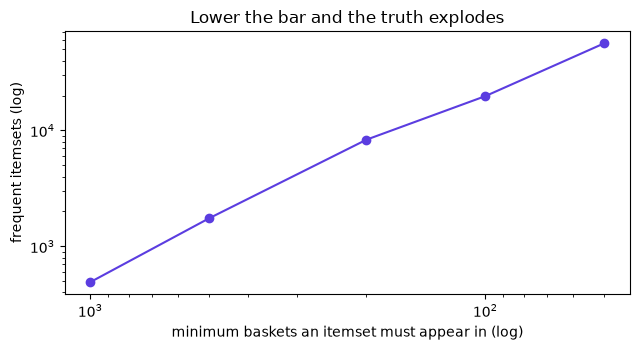

In [10]:
counts = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.plot(counts["min baskets"], counts["itemsets"], "o-", color="#5b3de0")
ax.set_xscale("log"); ax.set_yscale("log")
ax.invert_xaxis()
ax.set_xlabel("minimum baskets an itemset must appear in (log)")
ax.set_ylabel("frequent itemsets (log)")
ax.set_title("Lower the bar and the truth explodes")
plt.tight_layout()
plt.show()

491 itemsets at 1%, 56,470 at 0.05%: the threshold is one of the biggest choices in the experiment.

## Why is each itemset frequent?

Labels: **single** (one item) · **planted** (one of the 32) · **part** (a piece of a planted set) · **extension**
(≥ 2 items of a planted set plus others) · **chance** (none of those).

In [11]:
def my_classify(itemset, planted):
    if len(itemset) == 1:
        return "single"
    sets = [frozenset(p.items) for p in planted]
    if itemset in sets:
        return "planted"
    if any(itemset < s for s in sets):
        return "part"
    if any(len(itemset & s) >= 2 for s in sets):
        return "extension"
    return "chance"


labels = {itemset: my_classify(itemset, data.planted) for itemset in truth}
print("same labels as the reference for all", f"{len(labels):,}", "itemsets:",
      all(labels[i] == classify_itemset(i, data.planted) for i in truth))

same labels as the reference for all 56,470 itemsets: True


In [12]:
table = pd.DataFrame({"size": [len(i) for i in truth], "label": list(labels.values())})
summary = table["label"].value_counts().reindex(["single", "planted", "part", "extension", "chance"])
print(summary.to_string())
print(f"\nplanted are {summary['planted'] / len(truth):.2%} of the truth")

label
single         977
planted         32
part           303
extension    31902
chance       23256

planted are 0.06% of the truth


label  single  planted  part  extension  chance
size                                           
1         977        0     0          0       0
2           0        8   151          0   18078
3           0        8   112      11231    5177
4           0        8    40      13003       1
5           0        8     0       7668       0


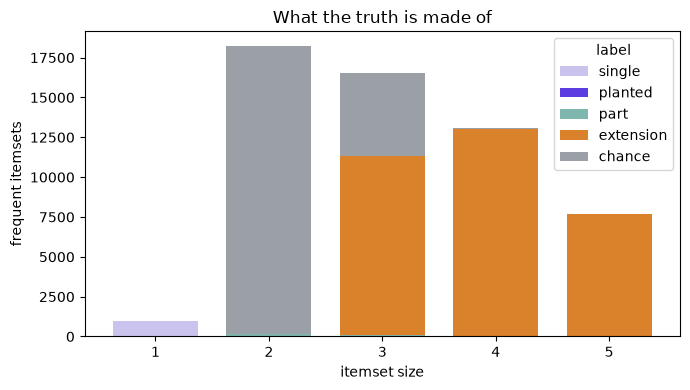

In [13]:
crosstab = pd.crosstab(table["size"], table["label"])[["single", "planted", "part", "extension", "chance"]]
print(crosstab)
colors = ["#c9c3ee", "#5b3de0", "#7fb7ae", "#d9822b", "#9aa0a6"]
ax = crosstab.plot.bar(stacked=True, figsize=(7, 4), color=colors, width=0.75)
ax.set_xlabel("itemset size")
ax.set_ylabel("frequent itemsets")
ax.set_title("What the truth is made of")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Pairs are almost all chance; 4- and 5-sets are almost all extensions. Planted = 32 of 56,470. About 98% of the
truth is extension or chance.

In [14]:
def example(label, size):
    pool = [(s, i) for i, s in truth.items() if labels[i] == label and len(i) == size]
    support, itemset = max(pool, key=lambda x: x[0])
    return f"{support:.2%}  " + " + ".join(sorted(itemset))

for label, size in (("planted", 3), ("part", 2), ("extension", 3), ("chance", 3)):
    print(f"{label:10}", example(label, size))

planted    5.00%  Brew Bazaar Tea Powder 250 g + Ghar Ghar Floor Cleaner 2 L + Kids Korner Notebook pack of 5
part       6.00%  Onion 1 kg + Tomato 500 g
extension  0.99%  Crunchy Crust Bread 400 g + Onion 1 kg + Tomato 500 g
chance     0.44%  Crunchy Crust Bread 400 g + Golden Drop Sunflower Oil 500 ml + Onion 1 kg


## Rules: A → B

Confidence = support(A and B) / support(A); lift = how many times more than chance. All computable from the truth.

In [15]:
common = {i: s for i, s in truth.items() if s >= 0.005 and len(i) <= 3}
found_rules = rules(common, min_confidence=0.3)

print(f"{len(found_rules)} rules at confidence >= 0.3 from {len(common)} itemsets\n")
for antecedent, consequent, support, confidence, lift in found_rules[:5]:
    print(f"{' + '.join(sorted(antecedent))}  ->  {' + '.join(sorted(consequent))}")
    print(f"     support {support:.2%}, confidence {confidence:.0%}, lift {lift:.1f}   [{labels[antecedent | consequent]}]")

1128 rules at confidence >= 0.3 from 1468 itemsets

Kesari Cumin Seeds 200 g  ->  Brinjal 1 kg + Chai Chaska Soft Drink 2 L
     support 1.00%, confidence 86%, lift 84.6   [planted]
Brinjal 1 kg + Chai Chaska Soft Drink 2 L  ->  Kesari Cumin Seeds 200 g
     support 1.00%, confidence 98%, lift 84.6   [planted]
Kesari Chaat Masala sachet 10 g  ->  Munch Mela Potato Chips Rs 5 pack + Rupa Rani Deodorant 100 ml
     support 1.00%, confidence 85%, lift 84.2   [part]
Munch Mela Potato Chips Rs 5 pack + Rupa Rani Deodorant 100 ml  ->  Kesari Chaat Masala sachet 10 g
     support 1.00%, confidence 99%, lift 84.2   [part]
Kesari Chaat Masala sachet 10 g  ->  Rupa Rani Deodorant 100 ml + Surya Grains Salt 1 kg
     support 1.00%, confidence 85%, lift 82.5   [part]


Top rules by lift come from planted sets and their parts — planting is what creates lift.

## Try it: a smaller question (≤ 3 items at 0.1%)

In [16]:
small = my_frequent_itemsets(baskets, 0.001, max_size=3)
print(f"{len(small):,} itemsets")
print(pd.Series([my_classify(i, data.planted) for i in small]).value_counts().to_string())

13,650 itemsets
chance       8128
extension    4399
single        906
part          205
planted        12


Only 12 of the 32 planted survive: size cap drops the 4s and 5s, threshold drops the rarest. How the truth is cut
changes what the test measures.

## What I built
An exact Apriori miner (plain, then bitset — ~200× faster) identical to the reference, and a labelling of why each
itemset is frequent. The answer key: 56,470 itemsets at 0.05%, of which only 32 were planted.

## Test yourself

**1. Why can Apriori skip a candidate triple if one of its pairs isn't frequent?**
Every basket holding the triple also holds each of its pairs, so the triple's support can't exceed any pair's. If a
pair is below the threshold the triple must be too, so there's no need to count it.

**2. What makes the bitset version so much faster than plain Apriori?**
Plain Apriori checks every candidate against every basket. With one bit per basket per item, "baskets holding all
these items" is a single AND of two big integers, and the count is one `bit_count()` — no loop over baskets.

**3. We planted 32 itemsets. Why does the truth hold 56,470?**
Lowering the bar to 50 baskets lets in lots more: parts of planted sets, extensions (a planted set plus whatever else
those shoppers bought), and chance combos of popular items. Only 0.06% of the truth is what we planted.

## My notes

Apriori stays exact while skipping almost everything, and the bitset trick makes 100,000 baskets take seconds instead of hours. Surprising: only 32 of the 56,470 true itemsets are the ones we planted; the rest are extensions and chance.